# Lorehaven pricing: analysis walkthrough

This notebook walks through how the recommendation was reached, in the order the work was done:
the data, how prices were actually assigned, why the price effects can be read as causal, how sensitive
customers are to price, who a discount actually wins, why members should be priced by tenure, what the
2019 $15 → $12 cut did, how the simulator works, and how all of it was checked.

**How to read it.** Every number comes from the project's code (`src/lorehaven/`) or from
`outputs/results/metrics.json`, the single source of truth also used by the write-up and the tool.
Labels used throughout:
- **Observed**: a count or rate taken straight from the data.
- **Estimate**: the output of a model, with the model and its assumption stated.
- **Assumption**: something chosen or not verifiable from the data.

**To re-run it.** Install the environment (`pip install -r requirements.txt`, `pip install -e .`, plus
`pip install notebook` for Jupyter). Place the three CSVs in `data/raw/` (or set `LOREHAVEN_DATA_DIR`), and
run `python -m lorehaven.pipeline` once. Sections marked *needs raw data* read the customer panel (about 1 GB in memory).

## Glossary

| Term | Meaning in this project |
|---|---|
| Quarter | One season. Quarter index 0 = winter 2017 … 11 = fall 2019 (assumption: seasons run winter → spring → summer → fall). |
| Region / sub-region | 6 fictional regions (e.g. Westeros), split into 20 sub-regions (`region_id`). |
| Treated regions | The 5 regions that got discounts and the 2019 cut to $12. |
| Panem | The one region with no discounts and a $15 price throughout; the only comparison group for the cut. |
| Prospect | Someone who was not a member last quarter. A **never-member** has never joined; a **lapsed** prospect (win-back) was a member before. |
| Member | Someone who was a member last quarter. |
| Tenure | Consecutive quarters as a member before this quarter. *First renewal* = 1, *second* = 2, *established* = 3 or more. |
| Base (list) price | $15, or $12 in treated regions from spring 2019. |
| Discount depth | Dollars off the base price: $0 (no offer) or $1–$5. |
| Sign-up rate | Share of prospects who are members this quarter. |
| Retention (stay) rate | Share of last quarter's members who are still members this quarter. |
| Engaged listener | Podcast-engagement propensity score ≥ 0.5 (chosen in section 6). |
| Uplift | Extra sign-up probability caused by a discount, relative to list price. |
| Logit / log-odds | log(p / (1 − p)). A logit model says log-odds change linearly with price. |
| Elasticity | % change in a rate for a 1% change in price. |
| LTV | Revenue per 1,000 new prospects over a horizon (12 quarters unless stated), at the prices actually paid. |
| Fixed effects (FE) | A separate baseline per group (e.g. per region × quarter), so comparisons are only made within that group. |
| DiD | Difference-in-differences: the change in treated regions minus the change in the comparison region. |
| OPE | Off-policy evaluation: valuing a policy that was not run, from data logged under a known random policy. |

In [1]:
import json
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from lorehaven import data_prep, models
from lorehaven.simulate import PricingPolicy, SEGMENTS, load_model, logistic, simulate

RESULTS = ROOT / "outputs" / "results"
EDA = ROOT / "outputs" / "eda"
METRICS = json.loads((RESULTS / "metrics.json").read_text())
value = lambda key: METRICS[key]["value"]          # read one number from the single source of truth

ORANGE, BLUE, AQUA, GREY = "#c46a00", "#2a78d6", "#1a9e8f", "#9aa3b2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
print(f"{len(METRICS):,} metrics loaded from outputs/results/metrics.json")

1,027 metrics loaded from outputs/results/metrics.json


## 1. The data *(needs raw data)*

Three files were provided:
- **`customer_panel.csv`**: one row per customer per quarter. It records ad exposure, the price offered or paid, whether a discount was offered, and whether the customer was a member.
- **`customer_propensities.csv`**: each customer's channel-engagement scores, refreshed every summer.
- **`aggregate.csv`**: marketing spend and activity by region and quarter.

`data_prep.build_analysis_table()` loads the panel with explicit data types and derives every column the
models use: status from last quarter, new sign-up (0 → 1), churn (1 → 0), base price, discount depth and tenure.

In [2]:
table = data_prep.build_analysis_table()
print(f"rows: {len(table):,}   customers: {table.customer_id.nunique():,}   quarters: {table.quarter_index.nunique()}")
print("duplicate customer x quarter rows:", table.duplicated(["customer_id", "quarter_index"]).sum())
table[["region_name", "quarter_index", "status", "member_tenure", "base_price", "discount_depth",
       "membership_price", "sign_up_flag", "new_signup", "churned", "customer_podcast_score"]].head(8)

rows: 6,121,068   customers: 510,089   quarters: 12


duplicate customer x quarter rows: 0


,region_name,quarter_index,status,member_tenure,base_price,discount_depth,membership_price,sign_up_flag,new_signup,churned,customer_podcast_score
0,westeros,0,never_prospect,0,15,3,12,0,0,0,0.2069
1,westeros,1,never_prospect,0,15,3,12,0,0,0,0.2069
2,westeros,2,never_prospect,0,15,0,15,0,0,0,0.2069
3,westeros,3,never_prospect,0,15,5,10,0,0,0,0.2069
4,westeros,4,never_prospect,0,15,0,15,0,0,0,0.2032
5,westeros,5,never_prospect,0,15,0,15,0,0,0,0.2032
6,westeros,6,never_prospect,0,15,0,15,0,0,0,0.2032
7,westeros,7,never_prospect,0,15,0,15,0,0,0,0.2032


**Status counts.** Each row is classified by what the customer was *last* quarter. Quarter 0 is treated as
the launch quarter, so nobody was a member before it. This is an assumption. It is supported by the fact
that in every region, quarter 0's `member_count` equals quarter 0's sign-ups.

In [3]:
table.status.value_counts().rename("rows").to_frame()

,rows
status,
never_prospect,4955350
member,741460
lapsed_prospect,424258


## 2. Data quality: values recorded as 0 that are really missing *(needs raw data)*

Two marketing fields contain zeros in quarters where spend was positive. Zero activity alongside positive
spend is not plausible, so these zeros are treated as **missing** (NaN), not as zero.
- **TV ratings:** Westeros in every winter.
- **Display impressions:** fall 2018, spring 2019 and fall 2019, in every region.

The display *propensity* score has the same problem: about 83% exact zeros in 2017, 0% in 2018 and 58% in 2019.
None of these fields enter the price models.

In [4]:
raw = pd.read_csv(data_prep.data_dir() / "aggregate.csv")
issues = pd.DataFrame({
    "issue": ["Westeros winter TV ratings = 0", "Display impressions = 0 while display spend > 0"],
    "rows": [((raw.region_name == "westeros") & (raw.season == "winter") & (raw.tv_ratings == 0)).sum(),
             ((raw.display_impressions == 0) & (raw.display_spend > 0)).sum()]})
cleaned = data_prep.load_aggregate()
issues["now missing after cleaning"] = [cleaned.tv_ratings.isna().sum(), cleaned.display_impressions.isna().sum()]
issues

,issue,rows,now missing after cleaning
0,Westeros winter TV ratings = 0,3,3
1,Display impressions = 0 while display spend > 0,18,18


## 3. How prices were actually assigned *(needs raw data)*

The answer decides how prices can be analysed:
- **Base price:** $15 everywhere. Then $12 from spring 2019 (quarter 9) in every non-Panem sub-region.
- **Prospects:** offered a discount 25% of the time.
- **Members:** offered a discount 100% of the time outside Panem.
- **Discount depth:** $1–$5, each about 20% of the time, re-drawn every quarter.
- **Panem:** never discounted.

In [5]:
treated = table[table.is_treated_region == 1]
summary = pd.DataFrame({
    "offer rate, treated prospects": [treated[treated.is_prospect == 1].discount_flag.mean()],
    "offer rate, treated members": [treated[treated.status == "member"].discount_flag.mean()],
    "offer rate, Panem": [table[table.is_treated_region == 0].discount_flag.mean()],
}).T.rename(columns={0: "share"})
depth_shares = treated[treated.discount_flag == 1].discount_depth.value_counts(normalize=True).sort_index().rename("share of offers")
display(summary, depth_shares.to_frame())
print("List price by quarter (treated vs Panem):")
table[table.discount_flag == 0].groupby(["quarter_index", "is_treated_region"]).membership_price.max().unstack().rename(
    columns={0: "Panem", 1: "treated"}).T

,share
"offer rate, treated prospects",0.2502
"offer rate, treated members",1.0000
"offer rate, Panem",0.0000


,share of offers
discount_depth,
1,0.1996
2,0.1999
3,0.2002
4,0.1999
5,0.2004


List price by quarter (treated vs Panem):


quarter_index,0,1,2,3,4,5,6,7,8,9,10,11
is_treated_region,,,,,,,,,,,,
Panem,15,15,15,15,15,15,15,15,15,15,15,15
treated,15,15,15,15,15,15,15,15,15,12,12,12


## 4. Is the assignment random? (why the price effects are causal)

Comparing customers at different prices within the same region and quarter gives the *causal* effect of
price, but only if who got which price was random. Two steps were tested:
1. **Whether a prospect gets an offer.**
2. **How deep the discount is** once one is offered.

**Standardized mean difference** for a covariate x between groups 1 and 0:

$$\text{SMD} = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{(s_1^2 + s_0^2)/2}}$$

- $\bar{x}_g$ = the covariate's mean in group g.
- $s_g^2$ = the covariate's variance in group g.
- |SMD| < 0.1 is the usual bar for "balanced". The SMD is in standard-deviation units, so it does not shrink with sample size.

The full checks (decile spreads, customer-ID patterns, joint F-tests, AUC) are in
`notebooks/eda/01_randomization_checks.py` and `outputs/eda/01_randomization_checks.txt`. Their main results:

In [6]:
eligibility = pd.read_csv(EDA / "01_balance_eligibility.csv")[["covariate", "mean_offered", "mean_not_offered", "SMD"]]
depth = pd.read_csv(EDA / "01_balance_depth.csv")[["covariate", "mean_$1_off", "mean_$5_off", "SMD_5_vs_1"]]
print("Largest |SMD|, offer vs no offer:", round(eligibility.SMD.abs().max(), 4),
      "| largest |SMD|, $5 vs $1 off:", round(depth.SMD_5_vs_1.abs().max(), 4))
print((EDA / "01_randomization_checks.txt").read_text().split("A. ")[1].split("\n")[0])
for line in (EDA / "01_randomization_checks.txt").read_text().splitlines():
    if line.startswith(("Joint test (covariates", "AUC")):
        print(line)
eligibility

Largest |SMD|, offer vs no offer: 0.0028 | largest |SMD|, $5 vs $1 off: 0.0046
ELIGIBILITY among prospects (n=3,346,845); overall offer rate = 0.2502
Joint test (covariates | sub-region+season FE): F=0.79, p=0.652, R2 increment from covariates=2.59e-06, full R2=8.92e-06
AUC of fitted assignment model = 0.5019  (0.5 = no predictive power)
Joint test (covariates | FE): F=0.69, p=0.753, R2 increment=5.30e-06, full R2=2.12e-05


,covariate,mean_offered,mean_not_offered,SMD
0,customer_tv_score,0.6880,0.6880,8.2707e-05
1,customer_radio_score,0.5203,0.5206,-7.4380e-04
2,customer_social_score,0.7474,0.7474,-8.9929e-05
3,customer_podcast_score,0.5044,0.5036,2.7249e-03
4,customer_display_score,0.1377,0.1378,-5.9017e-04
5,display_missing,0.4393,0.4395,-5.0856e-04
6,l_search_flag,0.3948,0.3947,7.5597e-05
7,l_social_ad_impressions,4.2559,4.2570,-3.1534e-04
8,l_podcast_ad_listen,3.8869,3.8809,9.1863e-04
9,lapsed,0.0819,0.0814,1.6826e-03


**Reading it.**
- **Offer vs no offer:** the largest imbalance is about 0.003, far below 0.1.
- **Predicting who gets an offer:** an AUC of 0.502 means the covariates do no better than a coin flip (0.5).
- **Joint test:** p = 0.65, so the covariates don't jointly predict assignment.

Two labelled caveats:
- **Offer eligibility is treated as random.** This is an *assumption* (A2): the brief says business rules decide it, but no observable reveals them.
- **Depth randomization is stated in the brief** and confirmed here.
- **Is the podcast score affected by treatment?** It is measured in summer, but a randomized winter or spring offer does not move it (difference ≤ 0.002), so the segment is not a post-treatment variable.

## 5. How sensitive are sign-ups and retention to price?

### 5a. Observed rates at each price
Within a base-price era, prices differ only because of the random draw. So these rates are directly comparable.

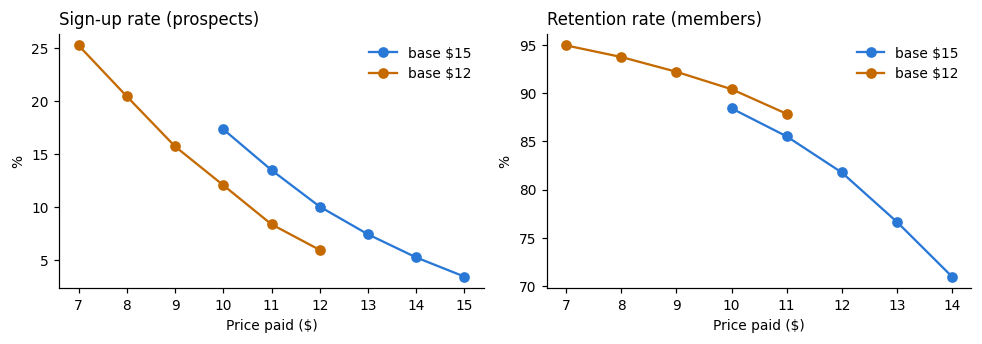

outcome          retention            signup         
era               base $12 base $15 base $12 base $15
membership_price                                     
7                    94.94      NaN    25.22      NaN
8                    93.74      NaN    20.42      NaN
9                    92.21      NaN    15.72      NaN
10                   90.41    88.42    12.07    17.33
11                   87.86    85.52     8.39    13.49
12                     NaN    81.78     5.98    10.05
13                     NaN    76.66      NaN     7.44
14                     NaN    70.98      NaN     5.27
15                     NaN      NaN      NaN     3.46

In [7]:
rates = pd.read_csv(RESULTS / "rates_by_price.csv")
rates["era"] = "base $" + rates.base_price.astype(str)
pivot = rates.pivot_table(index="membership_price", columns=["outcome", "era"], values="rate")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, outcome, title in ((axes[0], "signup", "Sign-up rate (prospects)"), (axes[1], "retention", "Retention rate (members)")):
    for era, color in (("base $15", BLUE), ("base $12", ORANGE)):
        series = pivot[(outcome, era)].dropna()
        ax.plot(series.index, 100 * series.values, marker="o", color=color, label=era)
    ax.set_title(title, loc="left"); ax.set_xlabel("Price paid ($)"); ax.set_ylabel("%"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
(100 * pivot).round(2)

### 5b. Elasticity, step by step

**Arc (midpoint) elasticity** between two adjacent prices $P_1 < P_2$ with rates $Q_1, Q_2$:

$$E_{arc} = \frac{(Q_2 - Q_1) \,/\, \tfrac{Q_1 + Q_2}{2}}{(P_2 - P_1) \,/\, \tfrac{P_1 + P_2}{2}}$$

- $Q_1, Q_2$ = the sign-up (or retention) rates at prices $P_1, P_2$.
- Both changes are measured against the midpoint, so the answer is the same in either direction.
- $E = -6$ means a 1% price increase loses about 6% of sign-ups.

In [8]:
q1, q2 = value("rates.signup.base15.price14"), value("rates.signup.base15.price15")
p1, p2 = 14, 15
pct_change_rate = (q2 - q1) / ((q1 + q2) / 2)
pct_change_price = (p2 - p1) / ((p1 + p2) / 2)
print(f"Sign-up, $14 -> $15 (base $15 era): Q1 = {q1:.4f}, Q2 = {q2:.4f}")
print(f"  % change in rate  = ({q2:.4f} - {q1:.4f}) / {((q1 + q2) / 2):.5f} = {pct_change_rate:+.3f}")
print(f"  % change in price = (15 - 14) / 14.5 = {pct_change_price:+.4f}")
print(f"  arc elasticity    = {pct_change_rate:.3f} / {pct_change_price:.4f} = {pct_change_rate / pct_change_price:.2f}")

Sign-up, $14 -> $15 (base $15 era): Q1 = 0.0527, Q2 = 0.0346
  % change in rate  = (0.0346 - 0.0527) / 0.04367 = -0.413
  % change in price = (15 - 14) / 14.5 = +0.0690
  arc elasticity    = -0.413 / 0.0690 = -5.99


**Logit model** (the curve the analysis and simulator use):

$$P(y_{it}=1) = \frac{1}{1 + e^{-(\alpha_{r,t} + \beta \cdot \text{price}_{it})}}$$

- $y_{it}$ = 1 if customer *i* signs up (prospects) or stays (members) in quarter *t*.
- $\alpha_{r,t}$ = a fixed effect for region *r* in quarter *t*. It absorbs base price, marketing and season, so customers are only compared with others in the same region and quarter.
- $\beta$ = change in log-odds per +$1 of price. $e^{\beta}$ is the factor that multiplies the odds.
- Standard errors are clustered by customer.

**Point elasticity** follows by differentiating:

$$E(p) = \frac{dP}{dp} \cdot \frac{p}{P} = \beta\, p\, (1 - P(p))$$

- $p$ = price; $P(p)$ = predicted rate at that price.

In [9]:
for name in ("acquisition", "retention"):
    beta = value(f"{name}.price.coef")
    print(f"{name:12s} beta = {beta:.4f} per $ (clustered SE {value(f'{name}.price.se_clustered'):.4f}); "
          f"each $1 OFF multiplies the odds by e^(-beta) = {math.exp(-beta):.3f}")
beta, p = value("retention.price.coef"), 14
P = value("rates.retention.base15.price14")
print(f"\nWorked example, retention at $14: E = beta * p * (1 - P) = {beta:.4f} * {p} * (1 - {P:.4f}) = {beta * p * (1 - P):.2f}")
elasticities = {k.split(".")[1] + " $" + k.split("price")[1]: value(k) for k in METRICS if k.startswith("elasticity.")}
pd.Series(elasticities, name="point elasticity (treated regions)").round(2).to_frame()

acquisition  beta = -0.3794 per $ (clustered SE 0.0012); each $1 OFF multiplies the odds by e^(-beta) = 1.461
retention    beta = -0.2787 per $ (clustered SE 0.0028); each $1 OFF multiplies the odds by e^(-beta) = 1.321

Worked example, retention at $14: E = beta * p * (1 - P) = -0.2787 * 14 * (1 - 0.7098) = -1.13


,point elasticity (treated regions)
acquisition $10,-3.19
acquisition $11,-3.69
acquisition $12,-4.26
acquisition $13,-4.61
acquisition $14,-5.07
acquisition $15,-5.51
acquisition $7,-1.92
acquisition $8,-2.39
acquisition $9,-2.88
retention $10,-0.30


**What it means for revenue.** First-quarter revenue per prospect is $R = p \cdot s(p)$, where $s(p)$ is the
sign-up probability. So $\frac{d \ln R}{d \ln p} = 1 + E_s$. Sign-up elasticity is below −1 at every tested
price, so **within the tested range, a lower price raises first-quarter revenue per prospect**. The best
price lies below the tested $7 floor, so it can't be read from this data. That is why the recommendation
says to *test* deeper discounts rather than extrapolate.

## 6. Which customers respond most? Choosing the podcast cutoff

The price slope was estimated within deciles of each propensity score. Only **podcast** engagement separates customers.
- **Below about 0.41:** sign-up is around 1%, and each $1 changes it by under 1pp.
- **Above about 0.54:** sign-up is around 14%, and each $1 changes it by about 5.6pp.

TV, radio and display showed no difference once compared within the same year. Radio and display scores
shift a lot between years, so pooling years had made them look predictive.

**Choosing the cutoff.** For each cutoff c, prospects were split into "score ≥ c" and "score < c", each half
got its own price slope, and the fit was compared using the residual sum of squares (RSS).

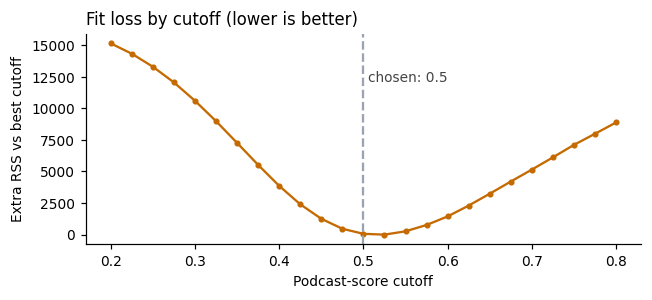

cutoff           0.5250
share_high       0.4068
slope_low_pp    -1.2408
slope_high_pp   -5.0901
Name: 13, dtype: float64

In [10]:
cut = pd.read_csv(EDA / "02b_ACQ_podcast_threshold.csv")
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(cut.cutoff, cut.delta_rss_vs_best, color=ORANGE, marker="o", markersize=3)
ax.axvline(0.5, color=GREY, linestyle="--"); ax.text(0.505, cut.delta_rss_vs_best.max() * 0.8, "chosen: 0.5", color="#444")
ax.set_xlabel("Podcast-score cutoff"); ax.set_ylabel("Extra RSS vs best cutoff"); ax.set_title("Fit loss by cutoff (lower is better)", loc="left")
plt.tight_layout(); plt.show()
cut.loc[cut.delta_rss_vs_best.idxmin(), ["cutoff", "share_high", "slope_low_pp", "slope_high_pp"]]

The best-fitting cutoff is 0.525, and **0.5** fits almost as well. 0.5 was chosen because it's a round
number that's easy to explain and to put into practice.

## 7. Who would join anyway vs who is persuaded by a discount

Offers were random, so within each segment the prospects who got no offer show what offered prospects would
have done at list price. For a $k discount:
- **Already sold** = $p_0$, the list-price sign-up rate. These people join anyway; the discount only costs money.
- **Persuadable** = uplift(k), the extra sign-ups caused by the discount.
- **Out of reach** = $1 - p_0 - \text{uplift}(k)$, the share who don't join even with $k off.
- **Incremental share of discounted sign-ups** = uplift(k) / ($p_0$ + uplift(k)).

These are shares of a segment, not labels on individuals. The split also *assumes* nobody is put off by
being offered a discount. All 20 uplift estimates in the $12 era are positive.

Uplift is estimated as $y = \alpha_{r,t} + \sum_k \tau_k \mathbb{1}[\text{depth}=k] + e$:
- $\tau_k$ = uplift of a $k discount, in rate points.
- $\alpha_{r,t}$ = a region × quarter baseline.

In [11]:
uplift = pd.read_csv(RESULTS / "uplift_by_segment_base12.csv").set_index("segment")
view = uplift[["share_of_prospects", "p0_list", "uplift_1", "uplift_3", "uplift_5", "incremental_share_at_5"]].copy()
view.columns = ["share of prospects", "already sold (list rate)", "uplift $1", "uplift $3", "uplift $5 (persuadable)", "incremental share at $5"]
(100 * view).round(1)

,share of prospects,already sold (list rate),uplift $1,uplift $3,uplift $5 (persuadable),incremental share at $5
segment,,,,,,
cold,64.7,0.5,0.7,4.7,12.4,96.1
lapsed_low_podcast,1.7,6.4,1.9,9.8,17.9,73.7
warm_listener,20.8,13.7,4.4,17.9,31.0,69.4
win_back,12.8,21.1,6.5,22.1,34.5,62.1


In [12]:
eff = pd.read_csv(RESULTS / "prospect_discount_efficiency.csv")
eff12 = eff[eff.base_price == 12].pivot(index="discount_depth", columns="segment", values="revenue_per_prospect")
print("First-quarter revenue per prospect ($) by discount depth, $12 era (observed, randomized):")
eff12.round(3)

First-quarter revenue per prospect ($) by discount depth, $12 era (observed, randomized):


segment,cold,lapsed_low_podcast,warm_listener,win_back
discount_depth,,,,
0,0.060,0.769,1.642,2.534
1,0.138,0.921,1.974,3.087
2,0.296,1.339,2.502,3.588
3,0.465,1.451,2.844,3.900
4,0.706,1.740,3.037,3.997
5,0.905,1.694,3.126,3.890


**Reading it.**
- Every segment brings in more first-quarter revenue with an offer than at list price. The discount is
  only paid by people who join, and 62–96% of those joiners are incremental.
- Win-backs peak at $4 off, but the curve is flat between $4 and $5.
- Targeting by segment (OPE, section 10) adds nothing measurable over a uniform $5 offer.

## 8. Members: why discounts should depend on tenure

Members in treated regions always got a random $1–$5 discount. So comparing members at different prices
within the same quarter is causal too. Splitting by tenure shows:
- **Established members mostly stay at any tested price.**
- **New members are the price-sensitive ones.**

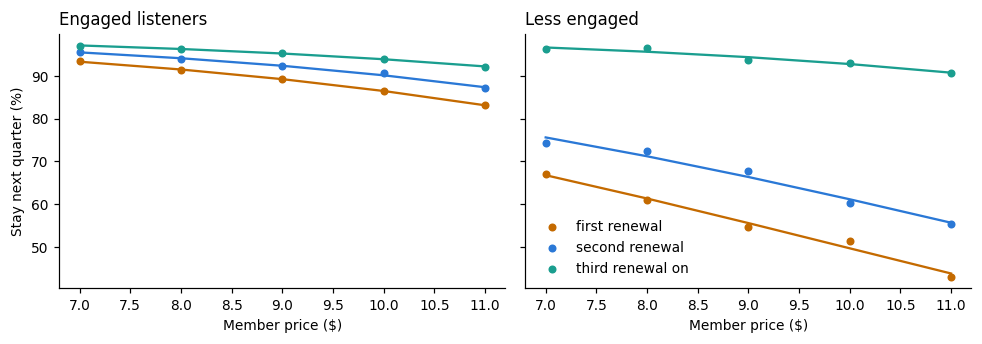

price                                 7     8     9     10    11
segment      status                                             
high_podcast member_established     97.0  96.3  95.3  93.9  92.1
             member_first_renewal   93.4  91.3  89.2  86.4  83.2
             member_second_renewal  95.5  94.0  92.2  90.6  87.1
low_podcast  member_established     96.4  96.4  93.6  93.0  90.7
             member_first_renewal   67.1  60.9  54.7  51.4  43.1
             member_second_renewal  74.2  72.5  67.7  60.4  55.3

In [13]:
fit = pd.read_csv(RESULTS / "model_fit_check_in_sample.csv")
members_fit = fit[fit.status.str.startswith("member")]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, segment, title in ((axes[0], "high_podcast", "Engaged listeners"), (axes[1], "low_podcast", "Less engaged")):
    for status, label, color in (("member_first_renewal", "first renewal", ORANGE), ("member_second_renewal", "second renewal", BLUE),
                                 ("member_established", "third renewal on", AQUA)):
        rows = members_fit[(members_fit.segment == segment) & (members_fit.status == status)]
        ax.plot(rows.price, 100 * rows.predicted, color=color); ax.scatter(rows.price, 100 * rows.observed, color=color, s=18, label=label)
    ax.set_title(title, loc="left"); ax.set_xlabel("Member price ($)")
axes[0].set_ylabel("Stay next quarter (%)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
members_fit.pivot_table(index=["segment", "status"], columns="price", values="observed").mul(100).round(1)

A $4 deeper discount ($11 → $7) buys:
- **About +10pp retention** at the first renewal for engaged listeners, and **+24pp** for less-engaged ones.
- **Only about +5–6pp** for established members.

Today's policy gives every member a random discount every quarter, so most of that budget goes to people
who would stay anyway. Pricing by tenure fixes that.

One thing tested and ruled out: do members react to a *change* in price from last quarter, beyond the price
itself? Last quarter's price effect is −0.11pp per $, which is negligible. Members respond to the level.

## 9. The 2019 base cut from $15 to $12 *(DiD; direction only)*

Model, for prospects at **list price** in all regions:

$$\text{logit}\,P(\text{sign-up}) = \alpha_{\text{region}} + \gamma_{t} + \delta \cdot \text{Treat} \times \text{Post}$$

- $\alpha_{\text{region}}$ = a region fixed effect; $\gamma_t$ = a quarter fixed effect.
- Treat = 1 for the five cut regions; Post = 1 from spring 2019.
- $\delta$ = the DiD effect on log-odds.

The **event study** replaces Treat × Post with one term per quarter, relative to winter 2019 (the last
quarter before the cut). Standard errors are clustered by sub-region. There are only 20 sub-regions and 6
of them are in Panem, so these errors should be read cautiously.

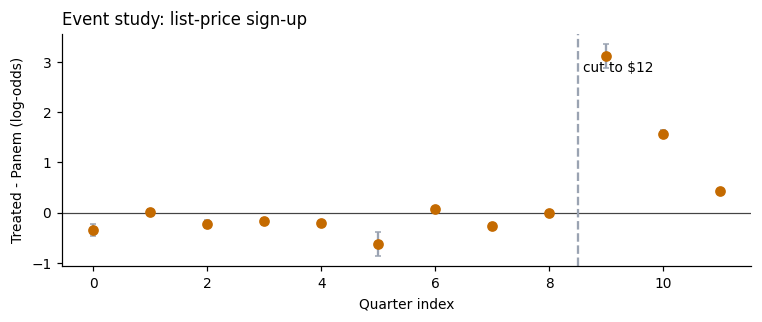

Pre-trend joint test p-value: 8.51e-52   (fails: treated and Panem were not parallel before the cut)
DiD delta = 0.840 log-odds; the randomized curve predicts 1.138 for a $3 cut


In [14]:
event = pd.read_csv(RESULTS / "event_study.csv", index_col=0)
event.index = [int(i.split("_q")[1]) for i in event.index]
event.loc[8] = [0.0, 0.0]; event = event.sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(event.index, event.coef, yerr=1.96 * event.se_subregion_clustered, fmt="o", color=ORANGE, ecolor=GREY, capsize=2)
ax.axhline(0, color="#444", linewidth=0.8); ax.axvline(8.5, color=GREY, linestyle="--"); ax.text(8.6, event.coef.max() * 0.9, "cut to $12")
ax.set_xlabel("Quarter index"); ax.set_ylabel("Treated - Panem (log-odds)"); ax.set_title("Event study: list-price sign-up", loc="left")
plt.tight_layout(); plt.show()
print(f"Pre-trend joint test p-value: {value('did.pretrend_p_value'):.2e}   (fails: treated and Panem were not parallel before the cut)")
print(f"DiD delta = {value('did.delta'):.3f} log-odds; the randomized curve predicts {value('did.randomized_prediction_delta'):.3f} for a $3 cut")

In [15]:
observed = pd.read_csv(RESULTS / "base_cut_observed.csv")
print("DESCRIPTIVE ONLY (not causal): 2019 spring-fall vs 2018 spring-fall")
observed.set_index(["group", "period"])[["members_per_customer_quarter", "revenue_per_customer_quarter", "revenue_per_member_quarter"]].round(3)

DESCRIPTIVE ONLY (not causal): 2019 spring-fall vs 2018 spring-fall


members_per_customer_quarter  revenue_per_customer_quarter  revenue_per_member_quarter
group   period                                                                                                  
panem   2018_spring_fall                         0.102                         1.532                      15.000
        2019_spring_fall                         0.140                         2.105                      15.000
treated 2018_spring_fall                         0.153                         1.890                      12.322
        2019_spring_fall                         0.295                         2.732                       9.256

**Conclusion.** The cut raised sign-ups in the regions that got it: the effect is positive and large in the
first quarter, then fades. Because pre-cut trends differ, **no effect size is claimed**.

Descriptively, revenue per customer grew more in the cut regions (+45%) than in Panem (+37%), even though
revenue per member fell 25%. Panem is the only comparison, so this is supporting evidence, not proof.

## 10. The simulator: how policies are compared

The simulator follows a cohort of 1,000 new prospects for H quarters. It tracks each podcast segment
separately, and within each segment four states: **never-members**, **lapsed** customers, and members at
**first renewal**, **second renewal** and **established**. Each quarter:

$$\text{join}_s = \sum_{\text{prices}} \text{share} \times \text{logistic}(a_s + b_s \cdot \text{price}) \qquad
\text{stay}_g = \text{logistic}(c_g + d_g \cdot \text{member price}_g)$$

- $s \in$ {never, lapsed}, each with its own intercept $a_s$ and price slope $b_s$.
- $g \in$ {first renewal, second renewal, established}, each with its own intercept $c_g$ and slope $d_g$.
- **Calibration:** curves are fit on the treated regions in the $12 regime (spring–fall 2019), without quarter fixed effects. This is valid because price was randomized in the same way every quarter, so the fit gives the *average-quarter* curve.
- **Prices:** new members pay the price they joined at; renewing members pay the member price for their tenure group.

$$\text{LTV} = \sum_{q=1}^{H} \frac{\text{revenue}_q}{(1+d)^{q-1}} \times \frac{1000}{N_0}$$

- $\text{revenue}_q$ = revenue in quarter *q*.
- $d$ = quarterly discount rate (default 0).
- $N_0$ = starting prospects.

In [16]:
model = load_model(RESULTS / "metrics.json")
params = pd.DataFrame({segment: vars(m) for segment, m in model.segments.items()})
print("Tested price ranges:", "prospects", model.tested_prospect_prices, "| members", model.tested_member_prices)
params.round(4)

Tested price ranges: prospects (7, 12) | members (7, 11)


,high_podcast,low_podcast
share_of_prospects,0.2431,0.7569
join_never_intercept,2.1832,2.9554
join_never_price_slope,-0.3349,-0.6754
join_lapsed_intercept,2.5767,1.2437
join_lapsed_price_slope,-0.3237,-0.3260
stay_first_renewal_intercept,4.4520,2.3554
stay_first_renewal_price_slope,-0.2599,-0.2368
stay_second_renewal_intercept,5.0090,2.7116
stay_second_renewal_price_slope,-0.2798,-0.2258
stay_established_intercept,5.3357,5.2280


In [17]:
everyone = lambda x: {s: x for s in SEGMENTS}
def ltv(**settings):
    return simulate(PricingPolicy(base_price=12, offer_share=everyone(1.0), prospect_discount=everyone(5.0),
                                  lapsed_get_offers=False, **settings), model)["kpis"]["ltv_per_1000_prospects"]

rows = []
for horizon in (12, 20, 40):
    uniform = {k: ltv(new_member_discount=float(k), established_member_discount=float(k), horizon_quarters=horizon) for k in range(1, 6)}
    best_k = max(uniform, key=uniform.get)
    rows.append({"horizon (quarters)": horizon,
                 "today's policy": simulate(PricingPolicy(base_price=12, random_depths=True, horizon_quarters=horizon), model)["kpis"]["ltv_per_1000_prospects"],
                 f"best single member discount": uniform[best_k], "its depth ($)": best_k,
                 "recommended ($5 new / $1 established)": ltv(new_member_discount=5.0, established_member_discount=1.0, horizon_quarters=horizon)})
pd.DataFrame(rows).set_index("horizon (quarters)").round(0)

,today's policy,best single member discount,its depth ($),recommended ($5 new / $1 established)
horizon (quarters),,,,
12,20228.0,42093.0,3,47037.0
20,41119.0,76340.0,3,85164.0
40,103798.0,164342.0,4,175721.0


**Reading it.** At every horizon, the tenure-based design beats the best single member discount, and both
far exceed today's policy. These are *simulated* results, calibrated to 2019 conditions: they compare
policies, they don't forecast.

In [18]:
ope = pd.read_csv(RESULTS / "off_policy_evaluation.csv")
print("Off-policy evaluation ($12 regime, first quarter only). Inverse-propensity estimate:")
print("  V(policy) = mean over prospects of  outcome x 1[action received = action the policy would give] / P(action received)")
ope[["policy", "signup_rate", "signup_rate_se", "first_quarter_revenue", "first_quarter_revenue_se"]].round(4)

Off-policy evaluation ($12 regime, first quarter only). Inverse-propensity estimate:
  V(policy) = mean over prospects of  outcome x 1[action received = action the policy would give] / P(action received)


,policy,signup_rate,signup_rate_se,first_quarter_revenue,first_quarter_revenue_se
0,status_quo_random_25pct,0.0858,0.0003,0.8852,0.0032
1,no_offers,0.0598,0.0003,0.7172,0.0036
2,offer_all_3_off,0.1572,0.0020,1.4145,0.0177
3,offer_all_5_off,0.2522,0.0025,1.7654,0.0175
4,high_podcast_only_5_off,0.1688,0.0020,1.2031,0.0142
5,targeted_depth,0.2432,0.0024,1.7700,0.0178


## 11. How everything was checked

| Check | What it tests | Where |
|---|---|---|
| Re-derivation of earlier EDA claims | Independent new code reproduces each claim, or flags it | `findings_verification.csv` |
| In-sample fit | Simulator curves vs the 2019 data they were fit on | `model_fit_check_in_sample.csv` |
| Backcast | Replays 2017–2019 with the simulator's own step function; out-of-sample: fit on 2017–18, predict 2019 | `backcast.csv` |
| Pull-forward | Does a deep offer this quarter steal next quarter's sign-ups? | `pull_forward.*` |
| Unit tests | Validation, edge cases, accounting, monotonicity, warnings, tool API | `tests/` (59 fast + 1 opt-in) |
| Independent critic (twice) | Fresh-context review of analysis and write-up | `logs/critic_phase2.md` |

In [19]:
verification = pd.read_csv(RESULTS / "findings_verification.csv")
print(verification.status.value_counts().to_string(), "\n")
verification[verification.status == "MISMATCH"][["claim", "claimed", "rederived", "note"]]

status
match       42
MISMATCH     4 



,claim,claimed,rederived,note
29,"retention price coefficient, podcast < 0.5",-0.084,-0.2203,EDA used a pooled price x segment interaction ...
42,strategy #6: deeper member discount raises val...,1.000,-1.0000,EDA used steady-state V = p r/(1-r) for one me...
43,strategy #6: deeper member discount raises val...,1.000,-1.0000,EDA used steady-state V = p r/(1-r) for one me...
44,strategy #6: deeper member discount raises val...,1.000,-1.0000,EDA used steady-state V = p r/(1-r) for one me...


**The flagged mismatches are kept, not hidden.** Each is a case where the earlier EDA was wrong:
- **Low-podcast retention slope:** a pooled model with shared fixed effects had mis-estimated it.
- **"Deep discounts for every member raise value":** this came from a steady-state formula that ignored tenure and members re-joining. The cohort simulation reverses it at 12 quarters and at 40 quarters with win-backs.

In [20]:
print(f"In-sample fit: mean |error| {100 * value('fit_check_in_sample.mean_abs_error'):.2f}pp, max {100 * value('fit_check_in_sample.max_abs_error'):.2f}pp")
backcast = {run: {"MAPE all": value(f"backcast.{run}.mape"), "MAPE treated": value(f"backcast.{run}.mape_treated"),
                  "MAPE Panem": value(f"backcast.{run}.mape_panem"), "end-2019 total error": value(f"backcast.{run}.total_error_q11_pct")}
            for run in ("in_sample", "out_of_sample_same_season", "out_of_sample_avg_2018")}
(100 * pd.DataFrame(backcast).T).round(1)

In-sample fit: mean |error| 0.26pp, max 2.13pp


,MAPE all,MAPE treated,MAPE Panem,end-2019 total error
in_sample,4.6,3.5,10.4,-0.5
out_of_sample_same_season,33.3,31.5,42.1,17.3
out_of_sample_avg_2018,15.2,9.6,43.1,-11.6


**Reading the backcast.**
- **MAPE** is the mean absolute percentage error of member counts, by region and quarter.
- **In sample:** the replay lands within 0.5% of actual end-2019 members.
- **Out of sample:** the "same season last year" baseline failed (33%). Panem had no price change and was worst, so the misses come from demand shocks, not from the price response.
- **Average-2018 baseline:** chosen *after* seeing that failure, and reported as such. It predicts the cut regions within about 10% but misses Panem by about 43%. So the simulator compares policies; it is not a forecasting tool.

In [21]:
for segment in ("high_podcast", "low_podcast"):
    later = value(f"pull_forward.{segment}.next_quarter_effect_per_dollar_now")
    now = value(f"pull_forward.{segment}.same_quarter_effect_per_dollar")
    print(f"{segment}: +{100 * now:.2f}pp sign-up per $ off this quarter; {100 * later:+.3f}pp next quarter "
          f"-> {100 * abs(later / now):.1f}% of the gain is pulled forward")

high_podcast: +5.31pp sign-up per $ off this quarter; -0.139pp next quarter -> 2.6% of the gain is pulled forward
low_podcast: +0.93pp sign-up per $ off this quarter; -0.012pp next quarter -> 1.3% of the gain is pulled forward


## 12. What changed along the way

Every accept, edit or reject of AI-generated work is in `logs/decision_log.csv`. The decisions that changed the answer:

In [22]:
log = pd.read_csv(ROOT / "logs" / "decision_log.csv")
print(f"{len(log)} logged decisions:", log.action.value_counts().to_dict())
key = log[log.action.isin(["reject", "edit"])][["phase", "agent", "suggestion", "action", "reason"]]
pd.set_option("display.max_colwidth", 120)
key

61 logged decisions: {'accept': 41, 'reject': 11, 'edit': 9}


,phase,agent,suggestion,action,reason
3,0,main,Update file paths in FINDINGS.md to notebooks/eda and outputs/eda,edit,Paths only; no claim or number changed (diff in Phase 0 commit)
4,0,main,Fix hard-coded import path in notebooks/eda/02b_thresholds.py after move,edit,Path only; script logic unchanged
11,0,main,Raw data stays in Iman cloud storage; data folder configurable via LOREHAVEN_DATA_DIR (default data/raw),edit,Iman: no extra copy needed; keeps data/raw gitignored convention without duplicating 430 MB
16,1,analyst,Clustered-SE implementation: dense row design would need ~4 GB,edit,"Rewrote meat as sparse per-customer score sums; same math, low memory"
18,1,analyst,Pooled price x segment interaction with shared FE (low-podcast retention slope -0.06; EDA -0.084),reject,Raw within-era log-odds slope is about -0.21; separate per-segment fits give -0.220. Shared FE misspecified the low-...
19,1,analyst,Lapsed customers modeled as intercept shift on never-member slope,reject,Over-predicted lapsed rejoin at $7 (66% vs 24% observed); fit never and lapsed separately
20,1,analyst,Simulator intercepts = average of 2019 quarter FE on log-odds scale,reject,"Fit check max error 18.8pp (Jensen + steeper full-sample slope). Switched to current-regime ($12, q9-q11) logit with..."
21,1,analyst,EDA strategy #6: deep member discounts raise member value (steady-state V = p r/(1-r)),reject,12-quarter cohort simulation: LTV falls with member discount beyond $1-2 under both win-back settings; flagged as MI...
22,1,analyst,Ad-hoc sensitivity (zero lapsed price slope) showing 53.8k LTV,reject,Own check was wrong: lapsed joiners were still charged the $7 offer price. Replaced by a proper lapsed_get_offers sw...
25,1,analyst,Pipeline output cleanup via rm of outputs/results/* blocked by safety check,reject,Not needed: pipeline overwrites every output on each run


## 13. Limitations

- **Single comparison region.** The base cut is judged against Panem alone, so its size is not identified.
- **Eligibility looks random but is assumed so** (A2). Depth randomization is stated in the brief.
- **Tested range only.** Prices are tested at $7–$12 for prospects and $7–$11 for members, both in the $12 regime. Deeper discounts, full price for established members, and base prices other than $12 are extrapolations and are flagged in the tool.
- **Strategic behaviour.** Customers who cancel in order to collect win-back offers can't be seen in this data. Pull-forward is measured and small.
- **Calibration.** Every simulated quarter is an average 2019 quarter: no seasonality, no marketing changes. Revenue is net of discounts; content costs are excluded.